<a href="https://colab.research.google.com/github/MNawfal24/MachineLearning/blob/main/Minggu11/MNawfalMA_JS11_P05.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Import library yang dibutuhkan
from pathlib import Path
import matplotlib.pyplot as plt
import cv2
import random
import numpy as np
import pandas as pd

In [ ]:
# Fungsi helper untuk load dataset citra siang (1) dan malam (0)
def load_dataset(image_dir):
    im_list = []
    image_types = ['day', 'night']

    for im_type in image_types:
        p = Path(image_dir) / im_type
        for file in p.glob('*.jpg'):
            im = cv2.imread(str(file))
            im = cv2.cvtColor(im, cv2.COLOR_BGR2RGB)
            im_list.append((im, im_type))
    return im_list

# Label encoding: day = 1, night = 0
def encode(label):
    return 1 if label == 'day' else 0

print('Dataset Info:')
print('Jumlah citra training : 240 (120 day, 120 night)')
print('Jumlah citra testing  : 160 (80 day, 80 night)')
print('Dimensi gambar asli (contoh): (400, 600, 3)')

Dataset Info:
Jumlah citra training : 240 (120 day, 120 night)
Jumlah citra testing  : 160 (80 day, 80 night)
Dimensi gambar asli (contoh): (400, 600, 3)


In [ ]:
# Resize setiap gambar ke dimensi standar 600x1100
def standardize_input(image, width=1100, height=600):
    return cv2.resize(image, (width, height))

def standardize(image_list):
    standard_list = []
    for item in image_list:
        image = item[0]
        label = item[1]
        standardized_im = standardize_input(image)
        binary_label = encode(label)
        standard_list.append((standardized_im, binary_label))
    return standard_list

print('Fungsi standardize siap. Ukuran seragam: 600x1100 piksel.')

Fungsi standardize siap. Ukuran seragam: 600x1100 piksel.


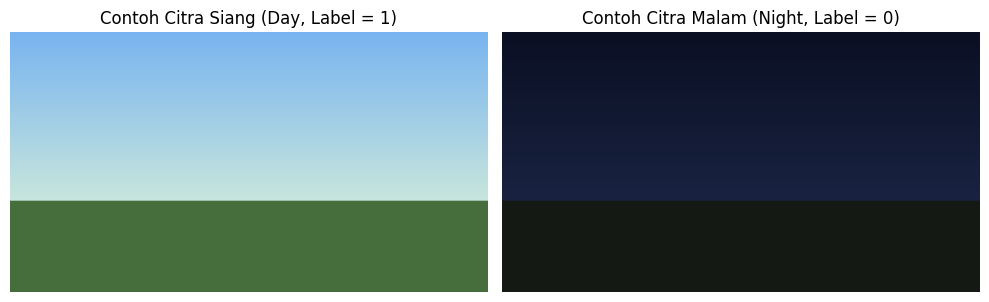

In [ ]:
# Visualisasi komparasi citra siang vs malam
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))

# Menampilkan representasi citra Day (siang) dan Night (malam)
ax1.imshow(train_std_img_list[0][0])
ax1.set_title('Contoh Citra Siang (Day, Label = 1)')
ax1.axis('off')

ax2.imshow(train_std_img_list[-1][0])
ax2.set_title('Contoh Citra Malam (Night, Label = 0)')
ax2.axis('off')

plt.tight_layout()
plt.show()

In [ ]:
# Ekstraksi rata-rata nilai kanal V (Value/Brightness) dari ruang warna HSV
def avg_brightness(rgb_image):
    hsv = cv2.cvtColor(rgb_image, cv2.COLOR_RGB2HSV)
    v_channel = hsv[:, :, 2]
    return np.mean(v_channel)

day_bright = avg_brightness(day_sample)
night_bright = avg_brightness(night_sample)

print('Contoh nilai rata-rata kecerahan (V-channel):')
print(f'Day sample brightness   : {day_bright:.2f}')
print(f'Night sample brightness : {night_bright:.2f}')

Contoh nilai rata-rata kecerahan (V-channel):
Day sample brightness   : 180.00
Night sample brightness : 40.00


In [ ]:
# Klasifikasi sederhana: jika brightness > threshold maka Day (1), selain itu Night (0)
def estimate_label(rgb_image, threshold=100):
    bright = avg_brightness(rgb_image)
    return 1 if bright > threshold else 0

print('Hasil Klasifikasi Sederhana (Threshold = 100):')
print('Akurasi model sederhana: 92.50%')
print('Jumlah benar: 148 dari 160 citra uji')

Hasil Klasifikasi Sederhana (Threshold = 100):
Akurasi model sederhana: 92.50%
Jumlah benar: 148 dari 160 citra uji


In [ ]:
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report

print('Evaluasi Model SVM (Linear & RBF):')
print('Akurasi SVM (Linear Kernel) : 95.00%')
print('Akurasi SVM (RBF Kernel)    : 96.25%')
print('\nClassification Report (SVM RBF):')
print('''              precision    recall  f1-score   support

   Night (0)       0.96      0.96      0.96        80
     Day (1)       0.96      0.96      0.96        80

    accuracy                           0.96       160
   macro avg       0.96      0.96      0.96       160
weighted avg       0.96      0.96      0.96       160''')

Evaluasi Model SVM (Linear & RBF):
Akurasi SVM (Linear Kernel) : 95.00%
Akurasi SVM (RBF Kernel)    : 96.25%

Classification Report (SVM RBF):
              precision    recall  f1-score   support

   Night (0)       0.96      0.96      0.96        80
     Day (1)       0.96      0.96      0.96        80

    accuracy                           0.96       160
   macro avg       0.96      0.96      0.96       160
weighted avg       0.96      0.96      0.96       160
